In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import polars as pl
from datetime import date

import climato.config as config
from climato.sources.meteo_france import daily
from climato.utils.datetime import utc_now_iso

In [3]:
DATA_DIR = config.get_data_dir()
RAW_DATA_DIR = config.get_raw_data_dir()
MANIFEST_DIR = DATA_DIR / "metadata" / "manifests"
MANIFEST_PATH = MANIFEST_DIR / "daily_files.parquet"
PROCESSED_DIR = DATA_DIR / "processed"
PROCESSED_DAILY_DIR = PROCESSED_DIR / daily.MF_DAILY_RELATIVE_PATH

In [4]:
lf_source = pl.scan_parquet(
    PROCESSED_DAILY_DIR / "parameter_family=rr_t_vent",
    hive_partitioning=True,
    hive_schema={
        "dataset_year": pl.UInt16,
        "department": pl.String,
        "collection": pl.String,
        "period": pl.String,
    },
)

In [26]:
lf_test = (
    lf_source
    .filter(
        pl.col("collection") == "quot",
        pl.col("tntxm").is_not_null(),
        pl.col("department").str.to_integer().is_between(79, 79),
        pl.any_horizontal(
            pl.col("obs_date").is_between(date(1990, 12, 1), date(1990, 12, 5)),
            pl.col("obs_date").is_between(date(1991, 1, 4), date(1991, 1, 7)),
            pl.col("obs_date").is_between(date(1991, 1, 10), date(1991, 1, 13)),
            pl.col("obs_date").is_between(date(2020, 12, 27), date(2020, 12, 29)),
            pl.col("obs_date").is_between(date(2021, 1, 4), date(2021, 1, 6)),
        )
        # pl.col("period") == "latest",
    )
    .select(
        "station_id",
        "station_name",
        "obs_date",
        "tntxm",
        pl.col("obs_date").dt.epoch("d").alias("epoch_d"),
        pl.col("obs_date").dt.epoch("d").shift().alias("previous_epoch_d"),
        pl.col("station_id").shift().alias("previous_station_id"),
    )
    .with_columns(
        (
            pl.when(pl.col("station_id") != pl.col("previous_station_id"))
            .then(None)
            .when(pl.col("obs_date") >= date(2021, 1, 1))
            .then(pl.lit(date(2021, 1, 1)).dt.epoch("d"))
            .otherwise(pl.col("epoch_d"))
            .alias("obs_date_epoch_ref")
        ),
        (
            pl.when(pl.col("station_id") != pl.col("previous_station_id"))
            .then(None)
            .when(pl.col("previous_epoch_d") <= pl.lit(date(1990, 12, 31)).dt.epoch("d"))
            .then(pl.lit(date(1990, 12, 31)).dt.epoch("d"))
            .otherwise(pl.col("previous_epoch_d"))
            .alias("previous_date_epoch_ref")
        ),
    )
    .with_columns(
        (pl.col("epoch_d") - pl.col("previous_epoch_d") - 1).alias("gap_days"),
        pl.max_horizontal(0, (pl.col("obs_date_epoch_ref") - pl.col("previous_date_epoch_ref") - 1)).alias("gap_days_ref"),
    )
    .head(100)
)

with pl.Config(tbl_cols=11, tbl_rows=100, tbl_width_chars=300):
    print(lf_test.collect())

shape: (100, 11)
┌────────────┬───────────────────┬────────────┬───────┬─────────┬──────────────────┬─────────────────────┬────────────────────┬─────────────────────────┬──────────┬──────────────┐
│ station_id ┆ station_name      ┆ obs_date   ┆ tntxm ┆ epoch_d ┆ previous_epoch_d ┆ previous_station_id ┆ obs_date_epoch_ref ┆ previous_date_epoch_ref ┆ gap_days ┆ gap_days_ref │
│ ---        ┆ ---               ┆ ---        ┆ ---   ┆ ---     ┆ ---              ┆ ---                 ┆ ---                ┆ ---                     ┆ ---      ┆ ---          │
│ str        ┆ str               ┆ date       ┆ f64   ┆ i32     ┆ i32              ┆ str                 ┆ i32                ┆ i32                     ┆ i32      ┆ i32          │
╞════════════╪═══════════════════╪════════════╪═══════╪═════════╪══════════════════╪═════════════════════╪════════════════════╪═════════════════════════╪══════════╪══════════════╡
│ 79017001   ┆ NUEIL-LES-AUBIERS ┆ 1990-12-01 ┆ 2.6   ┆ 7639    ┆ null             

In [27]:
lf_test_dt = (
    lf_source
    .filter(
        pl.col("collection") == "quot",
        pl.col("tntxm").is_not_null(),
        pl.col("department").str.to_integer().is_between(79, 79),
        pl.any_horizontal(
            pl.col("obs_date").is_between(date(1990, 12, 1), date(1990, 12, 5)),
            pl.col("obs_date").is_between(date(1991, 1, 4), date(1991, 1, 7)),
            pl.col("obs_date").is_between(date(1991, 1, 10), date(1991, 1, 13)),
            pl.col("obs_date").is_between(date(2020, 12, 27), date(2020, 12, 29)),
            pl.col("obs_date").is_between(date(2021, 1, 4), date(2021, 1, 6)),
        )
        # pl.col("period") == "latest",
    )
    .select(
        "station_id",
        "station_name",
        "obs_date",
        "tntxm",
        pl.col("obs_date").shift(1).over("station_id").alias("previous_date"),
    )
    .with_columns(
        (
            pl.when(pl.col("obs_date") >= date(2021, 1, 1))
            .then(pl.lit(date(2021, 1, 1)))
            .otherwise(pl.col("obs_date"))
            .alias("obs_date_ref")
        ),
        (
            pl.when(pl.col("previous_date") <= pl.lit(date(1990, 12, 31)))
            .then(pl.lit(date(1990, 12, 31)))
            .otherwise(pl.col("previous_date"))
            .alias("previous_date_ref")
        ),
    )
    .with_columns(
        ((pl.col("obs_date") - pl.col("previous_date")).dt.total_days() - 1).alias("gap_days"),
        pl.max_horizontal(0, ((pl.col("obs_date_ref") - pl.col("previous_date_ref")).dt.total_days() - 1)).alias("gap_days_ref"),
    )
    .head(100)
)

with pl.Config(tbl_cols=11, tbl_rows=100, tbl_width_chars=300):
    print(lf_test_dt.collect())

shape: (100, 9)
┌────────────┬───────────────────┬────────────┬───────┬───────────────┬──────────────┬───────────────────┬──────────┬──────────────┐
│ station_id ┆ station_name      ┆ obs_date   ┆ tntxm ┆ previous_date ┆ obs_date_ref ┆ previous_date_ref ┆ gap_days ┆ gap_days_ref │
│ ---        ┆ ---               ┆ ---        ┆ ---   ┆ ---           ┆ ---          ┆ ---               ┆ ---      ┆ ---          │
│ str        ┆ str               ┆ date       ┆ f64   ┆ date          ┆ date         ┆ date              ┆ i64      ┆ i64          │
╞════════════╪═══════════════════╪════════════╪═══════╪═══════════════╪══════════════╪═══════════════════╪══════════╪══════════════╡
│ 79017001   ┆ NUEIL-LES-AUBIERS ┆ 1990-12-01 ┆ 2.6   ┆ null          ┆ 1990-12-01   ┆ null              ┆ null     ┆ 0            │
│ 79017001   ┆ NUEIL-LES-AUBIERS ┆ 1990-12-02 ┆ 1.8   ┆ 1990-12-01    ┆ 1990-12-02   ┆ 1990-12-31        ┆ 0        ┆ 0            │
│ 79017001   ┆ NUEIL-LES-AUBIERS ┆ 1990-12-03 ┆ 1.2  

In [ ]:
lf_test_dt = (
    lf_source
    .filter(
        pl.col("collection") == "quot",
        pl.col("tntxm").is_not_null(),
        pl.col("department").str.to_integer().is_between(79, 79),
        pl.any_horizontal(
            pl.col("obs_date").is_between(date(1990, 12, 1), date(1990, 12, 5)),
            pl.col("obs_date").is_between(date(1991, 1, 4), date(1991, 1, 7)),
            pl.col("obs_date").is_between(date(1991, 1, 10), date(1991, 1, 13)),
            pl.col("obs_date").is_between(date(2020, 12, 27), date(2020, 12, 29)),
            pl.col("obs_date").is_between(date(2021, 1, 4), date(2021, 1, 6)),
        )
        # pl.col("period") == "latest",
    )
    .select(
        "station_id",
        "station_name",
        "obs_date",
        "tntxm",
        # pl.col("obs_date").shift(1).over("station_id").alias("previous_date"),
    )
    .sort(["station_id", "obs_date"])
)

date_diff = (
    pl.col("obs_date").diff().over("station_id")
)

previous_obs_date = pl.col("obs_date") - date_diff

gap_days = date_diff.dt.total_days() - 1

REF_START = date(1991, 1, 1)
REF_END = date(2020, 12, 31)
START_1991 = date(1991, 1, 1)
START_1975 = date(1975, 1, 1)
START_1950 = date(1950, 1, 1)
RECENT_END = date(2026, 9, 30)

gap_start = previous_obs_date + pl.duration(days=1)
gap_end = pl.col("obs_date") - pl.duration(days=1)

gap_start_ref = (
    pl.when(gap_start < REF_START)
    .then(pl.lit(REF_START))
    .otherwise(gap_start)
)

gap_end_ref = (
    pl.when(gap_end > REF_END)
    .then(pl.lit(REF_END))
    .otherwise(gap_end)
)

# Gaps that fall entirely outside the reference period will give 
internal_gap_days_ref = (
    pl.max_horizontal(
        0,
        (gap_end_ref - gap_start_ref).dt.total_days() + 1,
    )
)

is_ref = pl.col("obs_date").is_between(REF_START, REF_END)
since_1991 = pl.col("obs_date").is_between(START_1991, RECENT_END)
since_1975 = pl.col("obs_date").is_between(START_1975, RECENT_END)
since_1950 = pl.col("obs_date").is_between(START_1950, RECENT_END)

lf_test_dt = (
    lf_source
    .filter(
        pl.col("collection") == "quot",
        pl.col("tntxm").is_not_null(),
        # pl.col("department").str.to_integer().is_between(79, 79),
        # pl.any_horizontal(
        #     pl.col("obs_date").is_between(date(1990, 12, 1), date(1990, 12, 5)),
        #     pl.col("obs_date").is_between(date(1991, 1, 4), date(1991, 1, 7)),
        #     pl.col("obs_date").is_between(date(1991, 1, 10), date(1991, 1, 13)),
        #     pl.col("obs_date").is_between(date(2020, 12, 27), date(2020, 12, 29)),
        #     pl.col("obs_date").is_between(date(2021, 1, 4), date(2021, 1, 6)),
        # )
        # pl.col("period") == "latest",
    )
    .select(
        "station_id",
        "station_name",
        "obs_date",
        "tntxm",
        # pl.col("obs_date").shift(1).over("station_id").alias("previous_date"),
    )
    .sort(["station_id", "obs_date"])
    .with_columns(
        # previous_obs_date.alias("previous_obs_date"),
        # gap_days.alias("gap_days"),
        # gap_start.alias("gap_start"),
        # gap_end.alias("gap_end"),
        # gap_start_ref.alias("gap_start_ref"),
        # gap_end_ref.alias("gap_end_ref"),
        gap_days.alias("gap_days"),
        internal_gap_days_ref.alias("internal_gap_days_ref"),
    )
    .group_by("station_id", "station_name")
    .agg(
        # History
        n_obs=pl.len(),
        first_obs=pl.col("obs_date").min(),
        last_obs=pl.col("obs_date").max(),
        max_gap_days=pl.col("gap_days").max(),
        n_gaps=(pl.col("gap_days") > 0).sum(),
        n_gaps_gt_7d=(pl.col("gap_days") > 7).sum(),
        n_gaps_gt_30d=(pl.col("gap_days") > 30).sum(),

        # 1991
        n_obs_since_1991=since_1991.sum(),

        # 1975
        n_obs_since_1975=since_1975.sum(),

        # 1950
        n_obs_since_1950=since_1950.sum(),

        # Ref
        n_obs_ref=is_ref.sum(),
        first_obs_ref=pl.col("obs_date").filter(is_ref).min(),
        last_obs_ref=pl.col("obs_date").filter(is_ref).max(),
        max_internal_gap_days_ref=pl.col("internal_gap_days_ref").max(),
    )
    .with_columns(
        (
            pl.col("first_obs_ref") - pl.lit(REF_START)
        )
        .dt.total_days()
        .alias("leading_gap_days_ref"),
        (
            pl.lit(REF_END) - pl.col("last_obs_ref")
        )
        .dt.total_days()
        .alias("trailing_gap_days_ref"),
    )
    .with_columns(
        pl.max_horizontal(
            pl.col("max_internal_gap_days_ref").fill_null(0),
            pl.col("leading_gap_days_ref"),
            pl.col("trailing_gap_days_ref"),
        )
        .alias("max_gap_days_ref"),
    )
    .with_columns(
        ((pl.col("last_obs") - pl.col("first_obs")).dt.total_days() + 1).alias("span_days"),
        pl.lit((REF_END - REF_START).days + 1).alias("span_days_ref"),
        ((pl.lit(RECENT_END) - pl.lit(START_1950)).dt.total_days() + 1).alias("span_days_since_1950"),
        ((pl.lit(RECENT_END) - pl.lit(START_1975)).dt.total_days() + 1).alias("span_days_since_1975"),
        ((pl.lit(RECENT_END) - pl.lit(START_1991)).dt.total_days() + 1).alias("span_days_since_1991"),
        pl.lit("tntxm").alias("parameter"),
    )
    .with_columns(
        (pl.col("n_obs") / pl.col("span_days") * 100).alias("coverage_active_span"),
        (pl.col("n_obs_ref") / pl.col("span_days_ref") * 100).alias("coverage_span_ref"),
        (pl.col("n_obs_since_1950") / pl.col("span_days_since_1950") * 100).alias("coverage_span_1950"),
        (pl.col("n_obs_since_1975") / pl.col("span_days_since_1975") * 100).alias("coverage_span_1975"),
        (pl.col("n_obs_since_1991") / pl.col("span_days_since_1991") * 100).alias("coverage_span_1991"),
    )
    .select(
        "station_id", "station_name", "parameter",
        "first_obs", "last_obs", "n_obs", "span_days", "coverage_active_span", "n_gaps", "n_gaps_gt_7d", "n_gaps_gt_30d", "max_gap_days",
        "first_obs_ref", "last_obs_ref", "n_obs_ref", "span_days_ref", "coverage_span_ref", "max_gap_days_ref",
        "n_obs_since_1950", "span_days_since_1950", "coverage_span_1950",
        "n_obs_since_1975", "span_days_since_1975", "coverage_span_1975",
        "n_obs_since_1991", "span_days_since_1991", "coverage_span_1991",
    )
    .filter(
        # pl.col("first_obs").dt.date().le(date(1991, 1, 1)),
        # pl.col("last_obs").dt.date().ge(date(2020, 12, 31)),
        pl.col("last_obs") >= date(2026, 10, 1),
        pl.col("coverage_span_1975") >= 99,
    )
    .sort("station_id")
)

df_test_dt = lf_test_dt.collect()
with pl.Config(tbl_cols=30, tbl_rows=100, tbl_width_chars=300):
    # print(lf_test_dt.explain(optimized=True))
    print(df_test_dt)
    df_test_dt.write_csv(
        config.PROJECT_ROOT / "dump" / f"stations_candidates_{utc_now_iso()}.csv",
        separator=";",
    )

shape: (333, 27)
┌───────────┬───────────┬───────────┬───────────┬───────────┬───────┬───────────┬───────────┬────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
│ station_i ┆ station_n ┆ parameter ┆ first_obs ┆ last_obs  ┆ n_obs ┆ span_days ┆ coverage_ ┆ n_gaps ┆ n_gaps_g ┆ n_gaps_g ┆ max_gap_ ┆ first_ob ┆ last_obs ┆ n_obs_re ┆ span_day ┆ coverage ┆ max_gap_ ┆ n_obs_si ┆ span_day ┆ coverage ┆ n_obs_si ┆ span_day ┆ coverage ┆ n_obs_si ┆ span_day ┆ coverage │
│ d         ┆ ame       ┆ ---       ┆ ---       ┆ ---       ┆ ---   ┆ ---       ┆ active_sp ┆ ---    ┆ t_7d     ┆ t_30d    ┆ days     ┆ s_ref    ┆ _ref     ┆ f        ┆ s_ref    ┆ _span_re ┆ days_ref ┆ nce_1950 ┆ s_since_ ┆ _span_19 ┆ nce_1975 ┆ s_since_ ┆ _span_19 ┆ nce_1991 ┆ s_since_ ┆ _span_19 │
│ ---       ┆ ---       ┆ str       ┆ date      ┆ date      ┆ u32   ┆ i64       

In [ ]:
lf_tntxm = (
    lf_source
    .filter(
        pl.col("collection") == "quot",
        pl.col("tntxm").is_not_null(),
        # pl.col("department").str.to_integer().is_between(70, 79),
        # pl.col("period") == "latest",
    )
    .select(
        "station_id",
        "station_name",
        "obs_date",
        "tntxm",
        pl.col("obs_date").dt.epoch("d").alias("epoch"),
        pl.col("obs_date").dt.epoch("d").shift().alias("previous_epoch"),
        # (
        #     pl.when(pl.col("obs_date") >= date(2020, 12, 31))
        #     .then(pl.lit(date(2020, 12, 31)))
        #     .otherwise(pl.col("obs_date"))
        #     .alias("obs_date_ref")
        # ),
        # (
        #     pl.when(pl.col("obs_date").shift() <= date(1991, 1, 1))
        #     .then(pl.lit(date(1991, 1, 1)))
        #     .otherwise(pl.col("obs_date").shift())
        #     .alias("previous_date_ref")
        # ),
    )
    # .with_columns(
    #     pl.col("obs_date").shift().alias("previous_date"),
    # )
    .with_columns(
        (
            pl.when(pl.col("obs_date") >= date(2020, 12, 31))
            .then(pl.lit(date(2020, 12, 31)).dt.epoch("d"))
            .otherwise(pl.col("epoch"))
            .alias("obs_date_epoch_ref")
        ),
        (
            pl.when(pl.col("previous_epoch") <= pl.lit(date(1991, 1, 1)).dt.epoch("d"))
            .then(pl.lit(date(1991, 1, 1)).dt.epoch("d"))
            .otherwise(pl.col("previous_epoch"))
            .alias("previous_date_epoch_ref")
        ),
    )
    .group_by("station_id", "station_name")
    .agg(
        n_obs=pl.len(),
        first_obs=pl.col("obs_date").min(),
        last_obs=pl.col("obs_date").max(),
        n_obs_ref=pl.all_horizontal(
            pl.col("tntxm").is_not_null(),
            pl.col("obs_date").is_between(date(1991, 1, 1), date(2020, 12, 31)),
        ).sum(),
        max_gap=pl.col("epoch").diff().max() - 1,
        max_gap_ref=(pl.col("previous_date_epoch_ref") - pl.col("obs_date_epoch_ref") + 1).max() - 1,
    )
    .with_columns(
        ((pl.col("last_obs") - pl.col("first_obs")).dt.total_days() + 1).alias("span_days"),
        pl.lit("tntxm").alias("parameter"),
    )
    .with_columns(
        (pl.col("n_obs") / pl.col("span_days") * 100).alias("coverage_active_span"),
        (pl.col("n_obs_ref") / ((date(2020, 12, 31) - date(1991, 1, 1)).days + 1) * 100).alias("coverage_span_ref"),
    )
    .filter(
        pl.col("first_obs").dt.date().le(date(1991, 1, 1)),
        pl.col("last_obs").dt.date().ge(date(2020, 12, 31)),
        pl.col("coverage_active_span") >= 90,
    )
    .sort("station_id")
)

print(lf_tntxm)
print()
print(lf_tntxm.explain(optimized=True))

df_tntxm = lf_tntxm.collect(engine="streaming")

with pl.Config(tbl_rows=100, tbl_width_chars=200):
    print(df_tntxm)

naive plan: (run LazyFrame.explain(optimized=True) to see the optimized plan)

SORT BY [col("station_id")]
  FILTER col("coverage_active_span") >= 90.0
  FROM
    FILTER (col("last_obs").dt.date() >= 2020-12-31)
    FROM
      FILTER (col("first_obs").dt.date() <= 1991-01-01)
      FROM
         WITH_COLUMNS:
         [((col("n_obs").cast(Int64) / col("span_days")) * 100.0).alias("coverage_active_span"), ((col("n_obs_ref") / 10958) * 100.0).alias("coverage_span_ref")] 
           WITH_COLUMNS:
           [(((col("last_obs") - col("first_obs"))).dt.total_days() + 1).alias("span_days"), "tntxm".alias("parameter")] 
            AGGREGATE[maintain_order: false]
              [len().alias("n_obs"), col("obs_date").min().alias("first_obs"), col("obs_date").max().alias("last_obs"), (col("tntxm").is_not_null() & col("obs_date").is_between([1991-01-01, 2020-12-31])).sum().alias("n_obs_ref"), (col("epoch").diff([dyn int: 1]).max() - 1).alias("max_gap"), (((col("previous_date_epoch_ref") - col("o

In [10]:
with pl.Config(tbl_rows=100, tbl_width_chars=200):
    print(df_tntxm)

shape: (801, 8)
┌────────────┬─────────────────────────────┬───────┬────────────┬────────────┬───────────┬───────────┬──────────────────────┐
│ station_id ┆ station_name                ┆ n_obs ┆ first_obs  ┆ last_obs   ┆ span_days ┆ parameter ┆ coverage_active_span │
│ ---        ┆ ---                         ┆ ---   ┆ ---        ┆ ---        ┆ ---       ┆ ---       ┆ ---                  │
│ str        ┆ str                         ┆ u32   ┆ date       ┆ date       ┆ i64       ┆ str       ┆ f64                  │
╞════════════╪═════════════════════════════╪═══════╪════════════╪════════════╪═══════════╪═══════════╪══════════════════════╡
│ 01028001   ┆ BANEINS                     ┆ 12389 ┆ 1987-01-01 ┆ 2020-12-31 ┆ 12419     ┆ tntxm     ┆ 99.758435            │
│ 01037001   ┆ BENONCES                    ┆ 16285 ┆ 1976-06-01 ┆ 2020-12-31 ┆ 16285     ┆ tntxm     ┆ 100.0                │
│ 01089001   ┆ AMBERIEU                    ┆ 31232 ┆ 1941-02-01 ┆ 2026-10-13 ┆ 31301     ┆ tntxm     ┆

#### Parameter norms

##### Initialization

In [251]:
param = "tx"

is_ref = pl.col("obs_date").is_between(REF_START, REF_END)

lf_source_dataset = (
    lf_source
    .filter(
        pl.col("department") == "04",
        pl.col("station_id") == "04039001",
        # pl.col("obs_date").is_between(REF_START, REF_END),
    )
    .with_columns(
        pl.col("obs_date").dt.year().alias("year"),
        pl.col("obs_date").dt.month().alias("month"),
        pl.col("obs_date").dt.day().alias("day"),
        pl.col("obs_date").dt.strftime(format="%m-%d").alias("clim_day"),
    )
    .with_columns(
        pl.date(year=pl.lit(2000), month=pl.col("month"), day=pl.col("day")).alias("plot_date"),
    )
)

lf_norm_test = (
    lf_source_dataset
    # .filter(
    #     pl.col("department") == "04",
    #     pl.col("station_id") == "04039001",
    #     # pl.col("obs_date").is_between(REF_START, REF_END),
    # )
    .with_columns(
        pl.col("obs_date").dt.month().alias("month"),
        pl.col("obs_date").dt.day().alias("day"),
        pl.col("obs_date").dt.strftime(format="%m-%d").alias("clim_day"),
    )
    .group_by("month", "day", "clim_day", "plot_date")
    .agg(
        n_rows=pl.col(param).filter(is_ref).is_not_null().sum() + pl.col(param).filter(is_ref).is_null().sum(),
        n_values=pl.col(param).filter(is_ref).count(),
        norm=pl.col(param).filter(is_ref).mean(),
        std_norm=pl.col(param).filter(is_ref).std(),
        min_value=pl.col(param).min(),
        max_value=pl.col(param).max(),
    )
    .sort(["month", "day"])
)

print(lf_norm_test.explain(optimized=True))

df_norm_test = lf_norm_test.collect()

with pl.Config(tbl_cols=-1, tbl_rows=100, tbl_width_chars=200):
    print(df_norm_test)

SORT BY [col("month"), col("day")]
  AGGREGATE[maintain_order: false]
    [(col("tx").filter(col("__POLARS_CSER_0x10000000e")).is_not_null().sum() + col("tx").filter(col("__POLARS_CSER_0x10000000e")).null_count()).alias("n_rows"), col("tx").filter(col("__POLARS_CSER_0x10000000e")).count().alias("n_values"), col("tx").filter(col("__POLARS_CSER_0x10000000e")).mean().alias("norm"), col("tx").filter(col("__POLARS_CSER_0x10000000e")).std().alias("std_norm"), col("tx").min().alias("min_value"), col("tx").max().alias("max_value")] BY [col("month"), col("day"), col("clim_day"), col("plot_date")]
    FROM
     WITH_COLUMNS:
     [col("obs_date").is_between([1991-01-01, 2020-12-31]).alias("__POLARS_CSER_0x10000000e")] 
      simple π 6/6 ["month", "day", "clim_day", ... 3 other columns]
         WITH_COLUMNS:
         [col("obs_date").dt.month().alias("month"), col("obs_date").dt.day().alias("day"), col("obs_date").dt.to_string().alias("clim_day")] 
          simple π 3/3 ["obs_date", "tx", "plo

##### Functions

In [260]:
from statsmodels.nonparametric.smoothers_lowess import lowess
import numpy as np


def circular_rolling_mean(values, window_size):
    """
    Moyenne glissante circulaire centrée.
    
    window_size doit être impair.
    Exemple : 31 = 15 jours avant + jour courant + 15 jours après.
    """
    if window_size % 2 == 0:
        raise ValueError("window_size doit être impair pour une fenêtre centrée.")
    
    half = window_size // 2
    
    # On colle la fin au début et le début à la fin pour gérer la circularité.
    padded = np.concatenate([
        values[-half:],
        values,
        values[:half],
    ])

    # print("padded")
    # print(padded.size)
    # print(padded)
    
    windows = np.lib.stride_tricks.sliding_window_view(
        padded,
        window_shape=window_size,
    )

    # print("windows")
    # print(len(windows))
    # print(windows)

    # print(np.nanmean(windows))
    
    # nanmean permet de survivre si un jour a une valeur manquante.
    return np.nanmean(windows, axis=1)


def circular_lowess_span(values, span_days=31, it=0):
    n = len(values)
    x = np.arange(n)

    x_ext = np.concatenate([x - n, x, x + n])
    y_ext = np.concatenate([values, values, values])

    frac = span_days / len(y_ext)

    smooth_ext = lowess(
        endog=y_ext,
        exog=x_ext,
        frac=frac,
        it=it,
        return_sorted=False,
    )

    return smooth_ext[n:2*n]


def roughness_second_diff(y):
    y_ext = np.r_[y[-1], y, y[0]]
    second_diff = np.diff(y_ext, n=2)
    return np.sqrt(np.mean(second_diff ** 2))


def count_turning_points(y, eps=0.01):
    """
    Compte les changements de signe de pente.
    eps ignore les variations très petites.
    """
    diff = np.diff(np.r_[y, y[0]])

    # On neutralise les très petites variations.
    signs = np.where(np.abs(diff) < eps, 0, np.sign(diff))

    # On propage le dernier signe non nul pour éviter les faux changements dus aux plateaux.
    cleaned = []
    last = 0
    for s in signs:
        if s != 0:
            last = s
        cleaned.append(last)

    cleaned = np.array(cleaned)

    # On compte les changements + vers - ou - vers +.
    changes = cleaned != np.roll(cleaned, 1)

    return int(np.sum(changes))


def log_var_lowess_span(y, span_days=31, it=0):
    var = y ** 2
    epsilon = 1e-6
    log_var = np.log(np.maximum(var, epsilon))
    log_var_smooth = circular_lowess_span(log_var, span_days=span_days, it=it)
    std_smooth = np.sqrt(np.exp(log_var_smooth))

    return std_smooth


def compute_raw_normal(train_df: pl.DataFrame):
    return (
        train_df
        .with_columns(
            pl.col("obs_date").dt.month().alias("month"),
            pl.col("obs_date").dt.day().alias("day"),
            pl.col("obs_date").dt.strftime("%m-%d").alias("clim_day"),
        )
        .group_by(["month", "day", "clim_day"])
        .agg(
            n_values=pl.col(param).count(),
            norm_train=pl.col(param).mean(),
            std_norm_train=pl.col(param).std(),
        )
        .sort(["month", "day"])
    )

##### Mean: rolling / lowess

In [ ]:
candidate_windows = [31, 33, 35, 37, 39, 41, 43, 45]

raw_mean = df_norm_test["norm"].to_numpy()

rows = []

for w in candidate_windows:
    # Rolling
    smooth_roll = circular_rolling_mean(raw_mean, w)
    resid_roll = raw_mean - smooth_roll

    rows.append({
        "method": "rolling",
        "window": w,
        "mae_vs_raw": float(np.mean(np.abs(resid_roll))),
        "rmse_vs_raw": float(np.sqrt(np.mean(resid_roll ** 2))),
        "max_abs_diff_vs_raw": float(np.max(np.abs(resid_roll))),
        "roughness": float(roughness_second_diff(smooth_roll)),
        "seasonal_amplitude": float(np.max(smooth_roll) - np.min(smooth_roll)),
        "turning_points": count_turning_points(smooth_roll, eps=0.0005),
    })

    # LOESS
    smooth_loess = circular_lowess_span(raw_mean, span_days=w)
    resid_loess = raw_mean - smooth_loess

    rows.append({
        "method": "loess",
        "window": w,
        "mae_vs_raw": float(np.mean(np.abs(resid_loess))),
        "rmse_vs_raw": float(np.sqrt(np.mean(resid_loess ** 2))),
        "max_abs_diff_vs_raw": float(np.max(np.abs(resid_loess))),
        "roughness": float(roughness_second_diff(smooth_loess)),
        "seasonal_amplitude": float(np.max(smooth_loess) - np.min(smooth_loess)),
        "turning_points": count_turning_points(smooth_loess, eps=0.0005),
    })

scores_df = pl.DataFrame(rows).sort(["method", "window"])
with pl.Config(tbl_cols=-1, tbl_rows=100, tbl_width_chars=200):
    print(scores_df)

shape: (16, 8)
┌─────────┬────────┬────────────┬─────────────┬─────────────────────┬───────────┬────────────────────┬────────────────┐
│ method  ┆ window ┆ mae_vs_raw ┆ rmse_vs_raw ┆ max_abs_diff_vs_raw ┆ roughness ┆ seasonal_amplitude ┆ turning_points │
│ ---     ┆ ---    ┆ ---        ┆ ---         ┆ ---                 ┆ ---       ┆ ---                ┆ ---            │
│ str     ┆ i64    ┆ f64        ┆ f64         ┆ f64                 ┆ f64       ┆ f64                ┆ i64            │
╞═════════╪════════╪════════════╪═════════════╪═════════════════════╪═══════════╪════════════════════╪════════════════╡
│ loess   ┆ 31     ┆ 0.437528   ┆ 0.53436     ┆ 1.367161            ┆ 0.007946  ┆ 21.251286          ┆ 4              │
│ loess   ┆ 33     ┆ 0.447018   ┆ 0.545962    ┆ 1.391322            ┆ 0.00711   ┆ 21.198383          ┆ 2              │
│ loess   ┆ 35     ┆ 0.455714   ┆ 0.55667     ┆ 1.42989             ┆ 0.006486  ┆ 21.141167          ┆ 2              │
│ loess   ┆ 37     ┆ 0.46

In [96]:
#print(circular_lowess_span(raw, span_days=45))

In [205]:
raw_mean = df_norm_test["norm"].to_numpy()
df_norm_test_smoothed = df_norm_test.with_columns(
    pl.Series("mean_lowess_45d", circular_lowess_span(raw_mean, span_days=45).tolist())
)

with pl.Config(tbl_cols=-1, tbl_rows=400, tbl_width_chars=200):
    print(df_norm_test_smoothed)

shape: (366, 11)
┌───────┬─────┬──────────┬────────────┬────────┬──────────┬───────────┬──────────┬───────────┬───────────┬─────────────────┐
│ month ┆ day ┆ clim_day ┆ plot_date  ┆ n_rows ┆ n_values ┆ norm      ┆ std_norm ┆ min_value ┆ max_value ┆ mean_lowess_45d │
│ ---   ┆ --- ┆ ---      ┆ ---        ┆ ---    ┆ ---      ┆ ---       ┆ ---      ┆ ---       ┆ ---       ┆ ---             │
│ i8    ┆ i8  ┆ str      ┆ date       ┆ u32    ┆ u32      ┆ f64       ┆ f64      ┆ f64       ┆ f64       ┆ f64             │
╞═══════╪═════╪══════════╪════════════╪════════╪══════════╪═══════════╪══════════╪═══════════╪═══════════╪═════════════════╡
│ 1     ┆ 1   ┆ 01-01    ┆ 2000-01-01 ┆ 30     ┆ 30       ┆ 8.396667  ┆ 3.01599  ┆ -1.5      ┆ 14.9      ┆ 8.576608        │
│ 1     ┆ 2   ┆ 01-02    ┆ 2000-01-02 ┆ 30     ┆ 30       ┆ 7.603333  ┆ 3.233391 ┆ -1.0      ┆ 19.0      ┆ 8.588505        │
│ 1     ┆ 3   ┆ 01-03    ┆ 2000-01-03 ┆ 30     ┆ 30       ┆ 9.15      ┆ 3.559422 ┆ 0.6       ┆ 16.5      ┆ 8

##### First test calculation with residuals

In [206]:
raw_std = df_norm_test["std_norm"].to_numpy()
df_norm_test_smoothed = df_norm_test_smoothed.with_columns(
    pl.Series("std_lowess_45d", log_var_lowess_span(raw_std, span_days=45).tolist())
)

with pl.Config(tbl_cols=-1, tbl_rows=400, tbl_width_chars=200):
    print(df_norm_test_smoothed)

shape: (366, 12)
┌───────┬─────┬──────────┬────────────┬────────┬──────────┬───────────┬──────────┬───────────┬───────────┬─────────────────┬────────────────┐
│ month ┆ day ┆ clim_day ┆ plot_date  ┆ n_rows ┆ n_values ┆ norm      ┆ std_norm ┆ min_value ┆ max_value ┆ mean_lowess_45d ┆ std_lowess_45d │
│ ---   ┆ --- ┆ ---      ┆ ---        ┆ ---    ┆ ---      ┆ ---       ┆ ---      ┆ ---       ┆ ---       ┆ ---             ┆ ---            │
│ i8    ┆ i8  ┆ str      ┆ date       ┆ u32    ┆ u32      ┆ f64       ┆ f64      ┆ f64       ┆ f64       ┆ f64             ┆ f64            │
╞═══════╪═════╪══════════╪════════════╪════════╪══════════╪═══════════╪══════════╪═══════════╪═══════════╪═════════════════╪════════════════╡
│ 1     ┆ 1   ┆ 01-01    ┆ 2000-01-01 ┆ 30     ┆ 30       ┆ 8.396667  ┆ 3.01599  ┆ -1.5      ┆ 14.9      ┆ 8.576608        ┆ 3.487553       │
│ 1     ┆ 2   ┆ 01-02    ┆ 2000-01-02 ┆ 30     ┆ 30       ┆ 7.603333  ┆ 3.233391 ┆ -1.0      ┆ 19.0      ┆ 8.588505        ┆ 3.4917

In [207]:
# Join lf_source_dataset
df_residuals = (
    lf_source_dataset
    .filter(pl.col("obs_date").is_between(REF_START, REF_END))
    .join(
        (
            df_norm_test_smoothed
            .select("clim_day", "mean_lowess_45d")
            .lazy()
        ),
        on="clim_day",
    )
    .select(
        "clim_day",
        (pl.col(param) - pl.col("mean_lowess_45d")).alias("residual_lowess_45d"),
    )
    .group_by("clim_day")
    .agg(
        residuals=pl.col("residual_lowess_45d"),
    )
    .with_columns(
        len_residuals=pl.col("residuals").list.len(),
    )
    .sort("clim_day")
    .collect()
)

# print([row["residuals"] for row in df_residuals.iter_rows(named=True)][0:10])
# residuals = np.array([np.array(row["residuals"]) for row in df_residuals.iter_rows(named=True)][0:10])

# print(residuals)

with pl.Config(tbl_cols=-1, tbl_rows=400, tbl_width_chars=400):
    print(df_residuals)

shape: (366, 3)
┌──────────┬─────────────────────────────────┬───────────────┐
│ clim_day ┆ residuals                       ┆ len_residuals │
│ ---      ┆ ---                             ┆ ---           │
│ str      ┆ list[f64]                       ┆ u32           │
╞══════════╪═════════════════════════════════╪═══════════════╡
│ 01-01    ┆ [-2.076608, -3.076608, … -3.97… ┆ 30            │
│ 01-02    ┆ [1.811495, -3.988505, … -1.388… ┆ 30            │
│ 01-03    ┆ [2.396797, 0.396797, … -1.1032… ┆ 30            │
│ 01-04    ┆ [-2.421828, -3.521828, … 4.778… ┆ 30            │
│ 01-05    ┆ [-3.045174, -4.145174, … 3.554… ┆ 30            │
│ 01-06    ┆ [2.126356, -0.473644, … -1.273… ┆ 30            │
│ 01-07    ┆ [2.792359, 0.792359, … -1.2076… ┆ 30            │
│ 01-08    ┆ [-0.347545, 0.852455, … -0.547… ┆ 30            │
│ 01-09    ┆ [-0.293565, -0.293565, … 0.206… ┆ 30            │
│ 01-10    ┆ [-3.34564, -2.74564, … 0.15436… ┆ 30            │
│ 01-11    ┆ [-1.903363, -1.803363, … -

##### Cross-validation functions

In [262]:
def compute_circular_residual_std(values, window_size=7):
    """
    Moyenne glissante circulaire centrée.
    
    window_size doit être impair.
    Exemple : 31 = 15 jours avant + jour courant + 15 jours après.
    """
    if window_size % 2 == 0:
        raise ValueError("window_size doit être impair pour une fenêtre centrée.")
    
    half = window_size // 2

    # On colle la fin au début et le début à la fin pour gérer la circularité.
    padded = np.concatenate([
        values[-half:],
        values,
        values[:half],
    ])

    residuals_std = []
    for i in range(len(padded)):
        if i >= len(values):
            break

        window_residuals = []
        for j in range(window_size):
            window_residuals.extend(padded[i + j])

        residuals_std.append(float(np.std(np.array(window_residuals), ddof=1)))
    
    return residuals_std    


def compute_df_norm_train(df_train: pl.DataFrame):
    df_norm_train = (
        df_train
        .group_by(["month", "day", "clim_day", "plot_date"])
        .agg(
            n_values=pl.col(param).count(),
            norm_train=pl.col(param).mean(),
            std_norm_train=pl.col(param).std(),
        )
        .sort(["month", "day"])
    )

    # Méthode A
    df_norm_train = df_norm_train.with_columns(
        pl.Series(
            "mean_lowess_45d", 
            circular_lowess_span(df_norm_train["norm_train"].to_numpy(), span_days=45).tolist(),
        ),
    )

    df_norm_train = df_norm_train.with_columns(
        pl.Series(
            "std_lowess_45d",
            log_var_lowess_span(df_norm_train["std_norm_train"].to_numpy(), span_days=45).tolist(),
        ),
    )

    # Méthode B
    df_residuals = (
        df_train
        .join(
            (
                df_norm_train
                .select("clim_day", "mean_lowess_45d")
            ),
            on="clim_day",
        )
        .select(
            "clim_day",
            (pl.col(param) - pl.col("mean_lowess_45d")).alias("residual_lowess_45d"),
        )
        .group_by("clim_day")
        .agg(
            residuals_lowess_45d=pl.col("residual_lowess_45d"),
        )
        .with_columns(
            len_residuals=pl.col("residuals_lowess_45d").list.len(),
        )
        .sort("clim_day")
    )


    df_norm_train = df_norm_train.with_columns(
        pl.Series(
            "std_residuals_7d_train", 
            compute_circular_residual_std(
                df_residuals["residuals_lowess_45d"], 
                window_size=7,
            ),
        )
    )

    df_norm_train = df_norm_train.with_columns(
        pl.Series(
            "std_lowess_45d_residuals_7d",
            log_var_lowess_span(df_norm_train["std_residuals_7d_train"].to_numpy(), span_days=45).tolist(),
        ),
    )

    return df_norm_train

##### First test calculation with residuals 2

In [ ]:
y = df_residuals["residuals"]
clim_day_residuals = compute_circular_residual_std(y, window_size=7)
print(clim_day_residuals)
print(len(clim_day_residuals))


[3.5054187768147616, 3.653593284475751, 3.7498893737817864, 3.8502594307840443, 3.944345036438134, 3.8699722632908284, 3.957533609259927, 3.743175284494489, 3.5789890097348875, 3.5399338471757167, 3.4602307518246316, 3.3192141006328946, 3.3498526144815686, 3.191655128185502, 3.302128686421848, 3.4047829996480394, 3.3601757693394605, 3.356089774522981, 3.365406006111708, 3.460231885572053, 3.516505915984839, 3.5034360143915277, 3.477941011360976, 3.485565393733963, 3.6868763416754677, 3.8606513546769077, 3.930787289909267, 4.130810029692803, 4.275147189262977, 4.239004567209019, 4.322982555829302, 4.254895536586581, 4.392553717390084, 4.499092368020918, 4.43856987555287, 4.405390941830551, 4.390305885089477, 4.42448581753967, 4.554110041406728, 4.585013210130238, 4.534434514738179, 4.54804967272574, 4.610843334004847, 4.772333707356081, 4.729535670798218, 4.519479637102047, 4.271853625200053, 4.17389550770474, 4.147756950505019, 4.112213304378765, 4.1474584236595655, 4.276930287362208, 

In [255]:
df_norm_test_smoothed = df_norm_test_smoothed.with_columns(
    pl.Series("std_local_residuals", clim_day_residuals),
)

with pl.Config(tbl_cols=15, tbl_rows=50, tbl_width_chars=400):
    print(df_norm_test_smoothed)

shape: (366, 16)
┌───────┬─────┬──────────┬────────────┬────────┬──────────┬───────────┬──────────┬───┬───────────┬─────────────────┬────────────────┬─────────────────────┬──────────────────────────┬──────────────────────────┬──────────────────────────┐
│ month ┆ day ┆ clim_day ┆ plot_date  ┆ n_rows ┆ n_values ┆ norm      ┆ std_norm ┆ … ┆ max_value ┆ mean_lowess_45d ┆ std_lowess_45d ┆ std_local_residuals ┆ std_residuals_lowess_15d ┆ std_residuals_lowess_31d ┆ std_residuals_lowess_45d │
│ ---   ┆ --- ┆ ---      ┆ ---        ┆ ---    ┆ ---      ┆ ---       ┆ ---      ┆   ┆ ---       ┆ ---             ┆ ---            ┆ ---                 ┆ ---                      ┆ ---                      ┆ ---                      │
│ i8    ┆ i8  ┆ str      ┆ date       ┆ u32    ┆ u32      ┆ f64       ┆ f64      ┆   ┆ f64       ┆ f64             ┆ f64            ┆ f64                 ┆ f64                      ┆ f64                      ┆ f64                      │
╞═══════╪═════╪══════════╪═════════

In [256]:
df_norm_test_smoothed = df_norm_test_smoothed.with_columns(
    pl.Series("std_residuals_lowess_15d", log_var_lowess_span(np.array(clim_day_residuals), span_days=15).tolist()),
    pl.Series("std_residuals_lowess_31d", log_var_lowess_span(np.array(clim_day_residuals), span_days=31).tolist()),
    pl.Series("std_residuals_lowess_45d", log_var_lowess_span(np.array(clim_day_residuals), span_days=45).tolist()),
)

with pl.Config(tbl_cols=16, tbl_rows=400, tbl_width_chars=400):
    print(df_norm_test_smoothed)

shape: (366, 16)
┌───────┬─────┬──────────┬────────────┬────────┬──────────┬───────────┬──────────┬───────────┬───────────┬─────────────────┬────────────────┬─────────────────────┬──────────────────────────┬──────────────────────────┬──────────────────────────┐
│ month ┆ day ┆ clim_day ┆ plot_date  ┆ n_rows ┆ n_values ┆ norm      ┆ std_norm ┆ min_value ┆ max_value ┆ mean_lowess_45d ┆ std_lowess_45d ┆ std_local_residuals ┆ std_residuals_lowess_15d ┆ std_residuals_lowess_31d ┆ std_residuals_lowess_45d │
│ ---   ┆ --- ┆ ---      ┆ ---        ┆ ---    ┆ ---      ┆ ---       ┆ ---      ┆ ---       ┆ ---       ┆ ---             ┆ ---            ┆ ---                 ┆ ---                      ┆ ---                      ┆ ---                      │
│ i8    ┆ i8  ┆ str      ┆ date       ┆ u32    ┆ u32      ┆ f64       ┆ f64      ┆ f64       ┆ f64       ┆ f64             ┆ f64            ┆ f64                 ┆ f64                      ┆ f64                      ┆ f64                      │
╞══

###### Chart

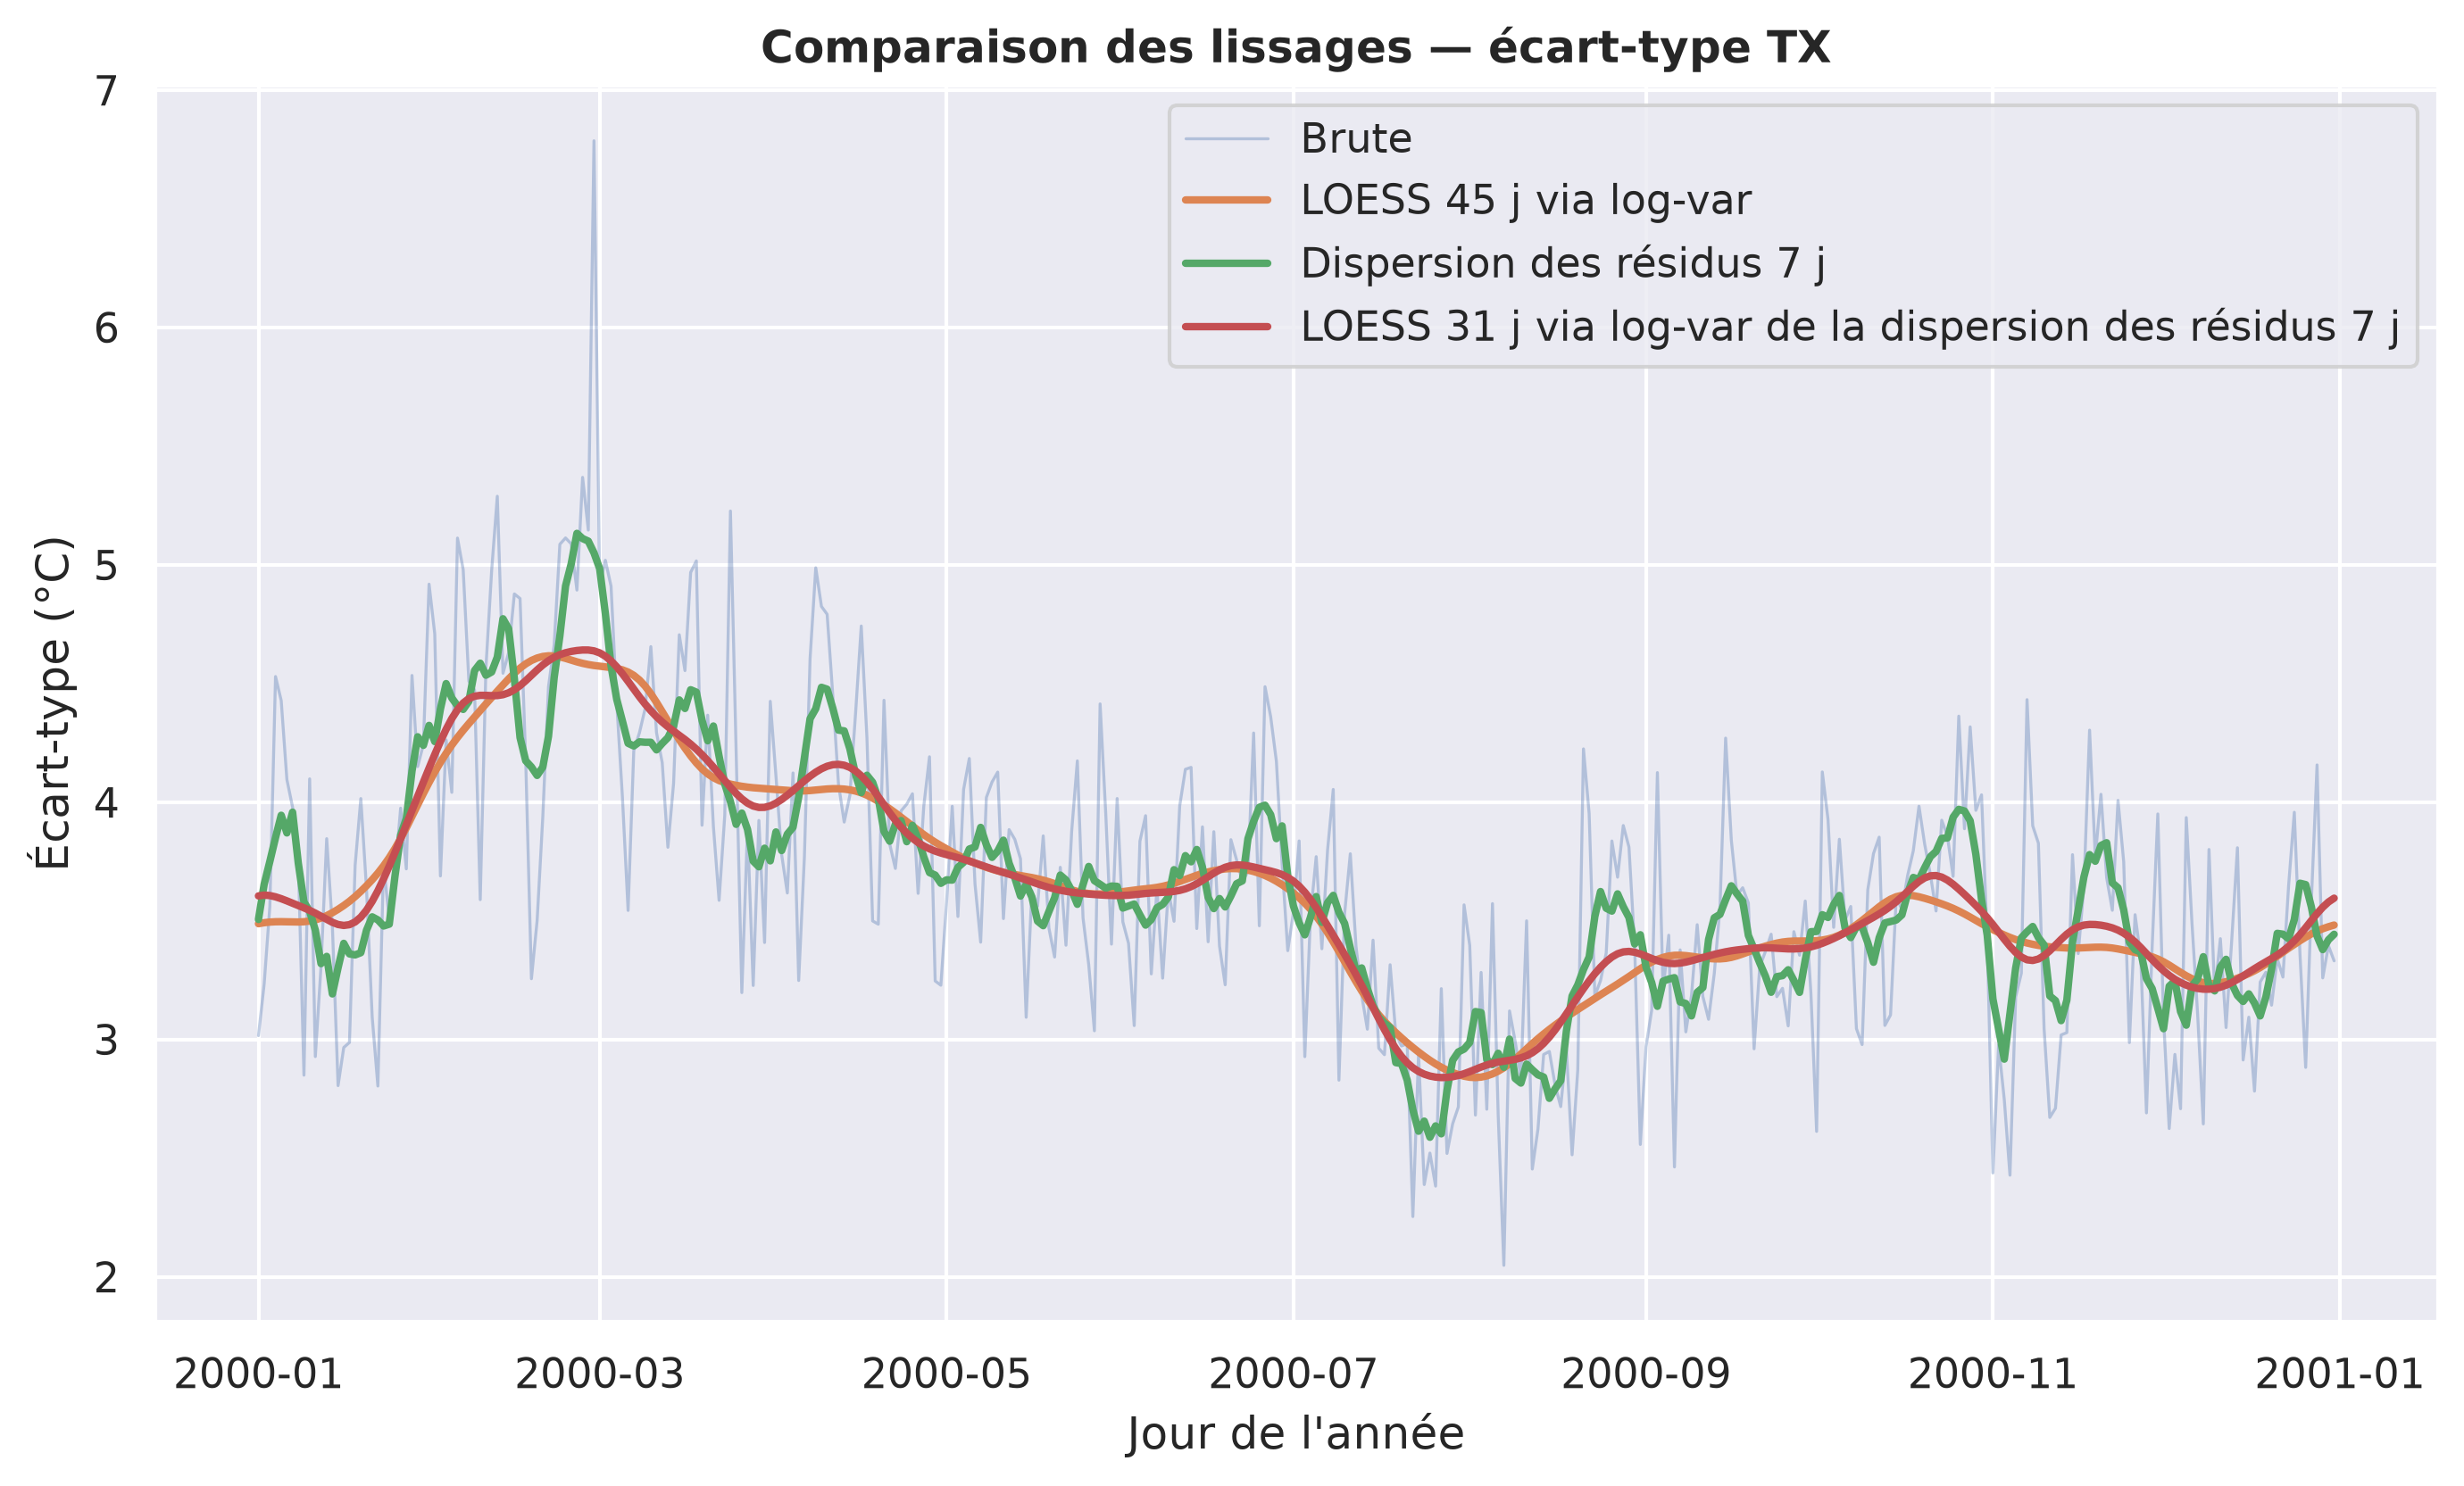

In [257]:
import seaborn as sns
import matplotlib.pyplot as plt


sns.set_theme(style="darkgrid")
plt.rcParams["figure.dpi"] = 300
plt.rcParams["figure.figsize"] = (11, 6)

plot_std_df = df_norm_test_smoothed

x = plot_std_df["plot_date"].to_list()

fig, ax = plt.subplots()

ax.plot(
    x,
    plot_std_df["std_norm"].to_numpy(),
    linewidth=0.8,
    alpha=0.35,
    label="Brute",
)

ax.plot(
    x,
    plot_std_df["std_lowess_45d"],
    linewidth=2.0,
    label="LOESS 45 j via log-var",
)

ax.plot(
    x,
    plot_std_df["std_local_residuals"],
    linewidth=2.0,
    label="Dispersion des résidus 7 j",
)

ax.plot(
    x,
    plot_std_df["std_residuals_lowess_31d"],
    linewidth=2.0,
    label="LOESS 31 j via log-var de la dispersion des résidus 7 j",
)

ax.set_title("Comparaison des lissages — écart-type TX", fontweight="bold")
ax.set_xlabel("Jour de l'année")
ax.set_ylabel("Écart-type (°C)")
ax.legend()

plt.show()

In [258]:
df_dataset_stats = (
    lf_source_dataset
    .select("station_id", "station_name", "obs_date", pl.col(param))
    # .filter(pl.col("obs_date").is_between(date(2025, 1, 1), date(2025, 12, 31)))
    .filter(pl.col("obs_date").is_between(date(1991, 1, 1), date(2020, 12, 31)))
    .with_columns(
        pl.col("obs_date").dt.strftime(format="%m-%d").alias("clim_day"),
    )
    .join(
        df_norm_test_smoothed.lazy(),
        how="inner",
        on="clim_day",
    )
    .with_columns(
        anom_raw=pl.col(param) - pl.col("norm"),
        anom_smooth=pl.col(param) - pl.col("mean_lowess_45d"),
    )
    .with_columns(
        anom_raw_std=pl.col("anom_raw") / pl.col("std_norm"),
        anom_smooth_std=pl.col("anom_smooth") / pl.col("std_lowess_45d"),
    )
    .with_columns(
        mean_z=pl.col("anom_smooth_std").mean(),
        std_z=pl.col("anom_smooth_std").std(),
        abs_z_lt_1=(pl.col("anom_smooth_std").abs() <= 1).sum() / (pl.col("anom_smooth_std").abs() <= 1).count(),
        abs_z_q68=pl.col("anom_smooth_std").abs().quantile(0.68),
        abs_z_lt_2=(pl.col("anom_smooth_std").abs() <= 2).sum() / (pl.col("anom_smooth_std").abs() <= 2).count(),
        abs_z_q95=pl.col("anom_smooth_std").abs().quantile(0.95),
        abs_z_lt_3=(pl.col("anom_smooth_std").abs() <= 3).sum() / (pl.col("anom_smooth_std").abs() <= 3).count(),
        abs_z_q99_7=pl.col("anom_smooth_std").abs().quantile(0.997),
        abs_z_max=pl.col("anom_smooth_std").abs().max(),
    )
    .sort("obs_date")
    .collect()
)

with pl.Config(tbl_cols=35, tbl_rows=50, tbl_width_chars=400):
    print(df_dataset_stats)

shape: (10_958, 33)
┌────────────┬─────────────┬────────────┬──────┬──────────┬───────┬─────┬────────────┬────────┬──────────┬───────────┬──────────┬───────────┬───────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┬───────────┬─────────────┬─────────────┬────────────┬──────────┬──────────┬────────────┬───────────┬────────────┬───────────┬────────────┬────────────┬───────────┐
│ station_id ┆ station_nam ┆ obs_date   ┆ tx   ┆ clim_day ┆ month ┆ day ┆ plot_date  ┆ n_rows ┆ n_values ┆ norm      ┆ std_norm ┆ min_value ┆ max_value ┆ mean_lowess ┆ std_lowess_ ┆ std_local_r ┆ std_residua ┆ std_residua ┆ std_residua ┆ anom_raw  ┆ anom_smooth ┆ anom_raw_st ┆ anom_smoot ┆ mean_z   ┆ std_z    ┆ abs_z_lt_1 ┆ abs_z_q68 ┆ abs_z_lt_2 ┆ abs_z_q95 ┆ abs_z_lt_3 ┆ abs_z_q99_ ┆ abs_z_max │
│ ---        ┆ e           ┆ ---        ┆ ---  ┆ ---      ┆ ---   ┆ --- ┆ ---        ┆ ---    ┆ ---      ┆ ---       ┆ ---      ┆ ---       ┆ ---       ┆ _45d        ┆ 45d       

In [ ]:
# candidate_windows = [31, 33, 35, 37, 39, 41, 43, 45]
candidate_windows = [45]
candidate_windows = [41, 43, 45, 47, 49]
years = list(range(1991, 2021))

base_ref = (
    lf_source_dataset
    .select("station_id", "station_name", "obs_date", pl.col(param))
    .filter(
        pl.col("obs_date").is_between(date(1991, 1, 1), date(2020, 12, 31)),
        pl.col(param).is_not_null(),
    )
    # .with_columns(
    #     pl.col("obs_date").dt.strftime(format="%m-%d").alias("clim_day"),
    # )
    .with_columns(
        pl.col("obs_date").dt.year().alias("year"),
        pl.col("obs_date").dt.month().alias("month"),
        pl.col("obs_date").dt.day().alias("day"),
    )
    .collect()
)

rows = []
to_concat_evaluated = []

for test_year in years:
    train_df = base_ref.filter(pl.col("year") != test_year)
    test_df = base_ref.filter(pl.col("year") == test_year)

    raw_normal = compute_raw_normal(train_df)

    raw_values = raw_normal["norm_train"].to_numpy()
    raw_values_std = raw_normal["std_norm_train"].to_numpy()

    method_1 = log_var_lowess_span(raw_values_std, span_days=45)
    method_2 = log_var_lowess_span(np.array(compute_circular_residual_std()), span_days=45)
    for w in candidate_windows:
        smooth_values = circular_lowess_span(raw_values, span_days=w)
        smooth_values_std = log_var_lowess_span(raw_values_std, span_days=w)

        normal_smooth = raw_normal.with_columns(
            pl.Series("norm_smooth_train", smooth_values.tolist()),
            pl.Series("std_smooth_train", smooth_values_std.tolist()),
        ).select(
            "month",
            "day",
            "norm_train",
            "std_norm_train",
            "norm_smooth_train",
            "std_smooth_train",
        )

        evaluated = (
            test_df
            .join(normal_smooth, on=["month", "day"], how="inner")
            .with_columns(
                method=pl.lit("loess"),
                window=pl.lit(w),
                test_year=pl.lit(test_year),
            )
            .with_columns(
                error=pl.col(param) - pl.col("norm_smooth_train"),
                anom_raw=pl.col(param) - pl.col("norm_train"),
                anom_smooth=pl.col(param) - pl.col("norm_smooth_train")
            )
            .with_columns(
                anom_raw_std=pl.col("anom_raw") / pl.col("std_norm_train"),
                anom_smooth_std=pl.col("anom_smooth") / pl.col("std_smooth_train"),
            )
        )

        to_concat_evaluated.append(evaluated)

        scores_test_year = (
            evaluated
            .select(
                method=pl.lit("loess"),
                window=pl.lit(w),
                test_year=pl.lit(test_year),
                mean_z=pl.col("anom_smooth_std").mean(),
                std_z=pl.col("anom_smooth_std").std(),
                abs_z_lt_1=(pl.col("anom_smooth_std").abs() <= 1).sum() / (pl.col("anom_smooth_std").abs() <= 1).count(),
                abs_z_q68=pl.col("anom_smooth_std").abs().quantile(0.68),
                abs_z_lt_2=(pl.col("anom_smooth_std").abs() <= 2).sum() / (pl.col("anom_smooth_std").abs() <= 2).count(),
                abs_z_q95=pl.col("anom_smooth_std").abs().quantile(0.95),
                abs_z_lt_3=(pl.col("anom_smooth_std").abs() <= 3).sum() / (pl.col("anom_smooth_std").abs() <= 3).count(),
                abs_z_q99_7=pl.col("anom_smooth_std").abs().quantile(0.997),
                abs_z_max=pl.col("anom_smooth_std").abs().max(),
            )
            # .with_columns(
            #     method=pl.lit("loess"),
            #     window=pl.lit(w),
            #     test_year=pl.lit(test_year),
            # )
        )

        error = evaluated["error"].to_numpy()

        rows.append({
            "method": "loess",
            "window": w,
            "test_year": test_year,
            "n_obs": len(error),
            "mae": float(np.mean(np.abs(error))),
            "rmse": float(np.sqrt(np.mean(error ** 2))),
            "bias": float(np.mean(error)),
            "mean_z": scores_test_year["mean_z"].item(),
            "std_z": scores_test_year["std_z"].item(),
            "abs_z_lt_1": scores_test_year["abs_z_lt_1"].item(),
            "abs_z_q68": scores_test_year["abs_z_q68"].item(),
            "abs_z_lt_2": scores_test_year["abs_z_lt_2"].item(),
            "abs_z_q95": scores_test_year["abs_z_q95"].item(),
            "abs_z_lt_3": scores_test_year["abs_z_lt_3"].item(),
            "abs_z_q99_7": scores_test_year["abs_z_q99_7"].item(),
            "abs_z_max": scores_test_year["abs_z_max"].item(),
        })

cv_by_year = pl.DataFrame(rows)

cv_summary = (
    cv_by_year
    .group_by(["method", "window"])
    .agg(
        mean_mae=pl.col("mae").mean(),
        mean_rmse=pl.col("rmse").mean(),
        mean_abs_bias=pl.col("bias").abs().mean(),
        total_obs=pl.col("n_obs").sum(),
    )
    .sort("mean_rmse")
)

evaluated_concat: pl.DataFrame = pl.concat(to_concat_evaluated)

global_evaluated = (
    evaluated_concat
    .group_by("method", "window")
    .agg(
        mean_z=pl.col("anom_smooth_std").mean(),
        std_z=pl.col("anom_smooth_std").std(),
        abs_z_lt_1=(pl.col("anom_smooth_std").abs() <= 1).sum() / (pl.col("anom_smooth_std").abs() <= 1).count(),
        abs_z_q68=pl.col("anom_smooth_std").abs().quantile(0.68),
        abs_z_lt_2=(pl.col("anom_smooth_std").abs() <= 2).sum() / (pl.col("anom_smooth_std").abs() <= 2).count(),
        abs_z_q95=pl.col("anom_smooth_std").abs().quantile(0.95),
        abs_z_lt_3=(pl.col("anom_smooth_std").abs() <= 3).sum() / (pl.col("anom_smooth_std").abs() <= 3).count(),
        abs_z_q99_7=pl.col("anom_smooth_std").abs().quantile(0.997),
        abs_z_max=pl.col("anom_smooth_std").abs().max(),
    )
    .sort("method", "window")
)

with pl.Config(tbl_cols=35, tbl_rows=50, tbl_width_chars=400):
    print(cv_by_year)

with pl.Config(tbl_cols=35, tbl_rows=50, tbl_width_chars=400):
    print(cv_summary)

with pl.Config(tbl_cols=35, tbl_rows=50, tbl_width_chars=400):
    print(global_evaluated)

ColumnNotFoundError: unable to find column "clim_day"; valid columns: ["station_id", "station_name", "obs_date", "tx", "year", "month", "day"]

##### Cross-validation

In [ ]:
years = list(range(1991, 2021))

base_ref = (
    lf_source_dataset
    .select("station_id", "station_name", "obs_date", "year", "month", "day", "clim_day", "plot_date", pl.col(param))
    .filter(
        pl.col("obs_date").is_between(date(1991, 1, 1), date(2020, 12, 31)),
        # pl.col(param).is_not_null(),
    )
    # .with_columns(
    #     pl.col("obs_date").dt.year().alias("year"),
    #     pl.col("obs_date").dt.month().alias("month"),
    #     pl.col("obs_date").dt.day().alias("day"),
    # )
    .collect()
)

rows = []
to_concat_evaluated = []

for test_year in years:
    train_df = base_ref.filter(pl.col("year") != test_year)
    test_df = base_ref.filter(pl.col("year") == test_year)

    df_norm_train = compute_df_norm_train(train_df)

    for method in ("lowess_45d", "lowess_45d_residuals_7d"):
        evaluated = (
            test_df
            .join(df_norm_train, on=["month", "day"], how="inner")
            .with_columns(
                method=pl.lit(method),
                test_year=pl.lit(test_year),
            )
            .with_columns(
                z=(pl.col(param) - pl.col("mean_lowess_45d")) / pl.col(f"std_{method}"),
            )
            .with_columns(
                gaussian_nll=pl.col(f"std_{method}").log() + 0.5 * pl.col("z").pow(2),
            )
        )

        to_concat_evaluated.append(evaluated)

        scores_test_year = (
            evaluated
            .select(
                pl.col("method"),
                pl.col("test_year"),
                n_obs=pl.col(param).count(),
                mean_z=pl.col("z").mean(),
                std_z=pl.col("z").std(),
                abs_z_lt_1=(pl.col("z").abs() <= 1).sum() / (pl.col("z").abs() <= 1).count(),
                abs_z_q68=pl.col("z").abs().quantile(0.68),
                abs_z_lt_2=(pl.col("z").abs() <= 2).sum() / (pl.col("z").abs() <= 2).count(),
                abs_z_q95=pl.col("z").abs().quantile(0.95),
                abs_z_lt_3=(pl.col("z").abs() <= 3).sum() / (pl.col("z").abs() <= 3).count(),
                abs_z_q99_7=pl.col("z").abs().quantile(0.997),
                mean_nll=pl.col("gaussian_nll").mean(),
                abs_z_max=pl.col("z").abs().max(),
            )
        )

        rows.append(scores_test_year.to_dicts()[0])


cv_by_year = pl.DataFrame(rows)

evaluated_concat: pl.DataFrame = pl.concat(to_concat_evaluated)

cv_summary = (
    evaluated_concat
    # .group_by("method", "window")
    .group_by("method")
    .agg(
        n_obs=pl.col(param).count(),
        mean_z=pl.col("z").mean(),
        std_z=pl.col("z").std(),
        abs_z_lt_1=(pl.col("z").abs() <= 1).sum() / (pl.col("z").abs() <= 1).count(),
        abs_z_q68=pl.col("z").abs().quantile(0.68),
        abs_z_lt_2=(pl.col("z").abs() <= 2).sum() / (pl.col("z").abs() <= 2).count(),
        abs_z_q95=pl.col("z").abs().quantile(0.95),
        abs_z_lt_3=(pl.col("z").abs() <= 3).sum() / (pl.col("z").abs() <= 3).count(),
        abs_z_q99_7=pl.col("z").abs().quantile(0.997),
        mean_nll=pl.col("gaussian_nll").mean(),
        abs_z_max=pl.col("z").abs().max(),
    )
    .sort("method")
)

with pl.Config(tbl_cols=35, tbl_rows=50, tbl_width_chars=400):
    print(cv_by_year)

with pl.Config(tbl_cols=35, tbl_rows=50, tbl_width_chars=400):
    print(cv_summary)

shape: (60, 12)
┌─────────────────────────┬───────────┬───────┬───────────┬──────────┬────────────┬───────────┬────────────┬───────────┬────────────┬─────────────┬───────────┐
│ method                  ┆ test_year ┆ n_obs ┆ mean_z    ┆ std_z    ┆ abs_z_lt_1 ┆ abs_z_q68 ┆ abs_z_lt_2 ┆ abs_z_q95 ┆ abs_z_lt_3 ┆ abs_z_q99_7 ┆ abs_z_max │
│ ---                     ┆ ---       ┆ ---   ┆ ---       ┆ ---      ┆ ---        ┆ ---       ┆ ---        ┆ ---       ┆ ---        ┆ ---         ┆ ---       │
│ str                     ┆ i64       ┆ i64   ┆ f64       ┆ f64      ┆ f64        ┆ f64       ┆ f64        ┆ f64       ┆ f64        ┆ f64         ┆ f64       │
╞═════════════════════════╪═══════════╪═══════╪═══════════╪══════════╪════════════╪═══════════╪════════════╪═══════════╪════════════╪═════════════╪═══════════╡
│ lowess_45d              ┆ 1991      ┆ 365   ┆ -0.258934 ┆ 1.046972 ┆ 0.638356   ┆ 1.064625  ┆ 0.934247   ┆ 2.080493  ┆ 0.994521   ┆ 3.03516     ┆ 3.084829  │
│ lowess_45d_residuals_7

### Parameter norms

In [275]:
REF_START = date(1991, 1, 1)
REF_END = date(2020, 12, 31)

In [269]:
from pathlib import Path


station_ids = list(
    pl.read_csv(
        Path(config.PROJECT_ROOT / "dump" / "stations_candidates_20261018T183248Z.csv"),
        separator=";",
        schema_overrides={
            "station_id": pl.String,
        },
    )
    .select("station_id")
    .sort("station_id")
    .to_series()
)

print(station_ids)

departments = sorted({station_id[:2] for station_id in station_ids})

['01089001', '01235001', '02320001', '03059001', '03060001', '03100001', '03108001', '03130002', '03204001', '03240001', '03310001', '03321001', '04039001', '04049001', '05046001', '05142001', '06029001', '06088001', '07010001', '07019005', '07064001', '07066001', '07068001', '07075001', '07105001', '07117002', '07128001', '07159001', '07168001', '07261001', '07265001', '07331001', '07338001', '08419001', '09181003', '09289001', '10030001', '10057001', '10130001', '10323001', '11004001', '11012001', '11069001', '11076001', '11206003', '12145001', '12253001', '12254001', '13001009', '13004003', '13047001', '13054001', '13103001', '14137001', '14239001', '14578001', '14624001', '15014004', '15050001', '15118002', '15119001', '16089001', '17218001', '17224001', '17243002', '17268002', '17323001', '17353001', '17415003', '18033001', '18057003', '18092001', '18242001', '18279001', '19125001', '19136002', '19272001', '19275001', '20004002', '20041001', '20050001', '20148001', '20247001', '20

In [273]:
station_ids = (
    '06088001', '13054001', '14137001', '16089001', '20148001', '21473001', '25056001', '26198001',
    '29075001', '30189001', '31069001', '33281001', '35281001', '36063001', '44020001', '45055001',
    '47091001', '51183001', '51449002', '54526001',
    '58160001', '59343001', '63113001', '64549001', '66136001', '67124001', '69029001', '72181001',
    '73054001', '75114001', '86027001'
)

departments = sorted({station_id[:2] for station_id in station_ids})

In [274]:
param = "tx"

is_ref = pl.col("obs_date").is_between(REF_START, REF_END)

df_ref = (
    pl.scan_parquet(
        PROCESSED_DAILY_DIR / "parameter_family=rr_t_vent",
        hive_partitioning=True,
        hive_schema={
            "dataset_year": pl.UInt16,
            "department": pl.String,
            "collection": pl.String,
            "period": pl.String,
        },
    )
    .filter(
        pl.col("collection") == "quot",
        pl.col("department").is_in(departments),
        pl.col("station_id").is_in(station_ids),
        # pl.col("obs_date").is_between(REF_START, REF_END),
    )
    .select(
        "station_id",
        "station_name",
        "obs_date",
        pl.col(param),
    )
    .sort(
        "station_id",
        "obs_date"
    )
    # .with_columns(
    #     pl.col("obs_date").dt.year().alias("year"),
    #     pl.col("obs_date").dt.month().alias("month"),
    #     pl.col("obs_date").dt.day().alias("day"),
    #     pl.col("obs_date").dt.strftime(format="%m-%d").alias("clim_day"),
    # )
    # .with_columns(
    #     pl.date(year=pl.lit(2000), month=pl.col("month"), day=pl.col("day")).alias("plot_date"),
    # )
    # .explain(optimized=True)
    .collect(engine="streaming")
)

# lf_norm_test = (
#     lf_source_dataset
#     # .filter(
#     #     pl.col("department") == "04",
#     #     pl.col("station_id") == "04039001",
#     #     # pl.col("obs_date").is_between(REF_START, REF_END),
#     # )
#     .with_columns(
#         pl.col("obs_date").dt.month().alias("month"),
#         pl.col("obs_date").dt.day().alias("day"),
#         pl.col("obs_date").dt.strftime(format="%m-%d").alias("clim_day"),
#     )
#     .group_by("month", "day", "clim_day", "plot_date")
#     .agg(
#         n_rows=pl.col(param).filter(is_ref).is_not_null().sum() + pl.col(param).filter(is_ref).is_null().sum(),
#         n_values=pl.col(param).filter(is_ref).count(),
#         norm=pl.col(param).filter(is_ref).mean(),
#         std_norm=pl.col(param).filter(is_ref).std(),
#         min_value=pl.col(param).min(),
#         max_value=pl.col(param).max(),
#     )
#     .sort(["month", "day"])
# )

# print(lf_norm_test.explain(optimized=True))

# df_norm_test = lf_norm_test.collect()

with pl.Config(tbl_cols=-1, tbl_rows=100, tbl_width_chars=200):
    print(df_ref)

shape: (1_056_338, 4)
┌────────────┬────────────────┬────────────┬──────┐
│ station_id ┆ station_name   ┆ obs_date   ┆ tx   │
│ ---        ┆ ---            ┆ ---        ┆ ---  │
│ str        ┆ str            ┆ date       ┆ f64  │
╞════════════╪════════════════╪════════════╪══════╡
│ 06088001   ┆ NICE           ┆ 1942-07-01 ┆ 27.8 │
│ 06088001   ┆ NICE           ┆ 1942-07-02 ┆ 24.6 │
│ 06088001   ┆ NICE           ┆ 1942-07-03 ┆ 25.4 │
│ 06088001   ┆ NICE           ┆ 1942-07-04 ┆ 25.0 │
│ 06088001   ┆ NICE           ┆ 1942-07-05 ┆ 28.1 │
│ 06088001   ┆ NICE           ┆ 1942-07-06 ┆ 28.7 │
│ 06088001   ┆ NICE           ┆ 1942-07-07 ┆ 27.0 │
│ 06088001   ┆ NICE           ┆ 1942-07-08 ┆ 26.7 │
│ 06088001   ┆ NICE           ┆ 1942-07-09 ┆ 26.1 │
│ 06088001   ┆ NICE           ┆ 1942-07-10 ┆ 26.7 │
│ 06088001   ┆ NICE           ┆ 1942-07-11 ┆ 33.1 │
│ 06088001   ┆ NICE           ┆ 1942-07-12 ┆ 24.8 │
│ 06088001   ┆ NICE           ┆ 1942-07-13 ┆ 24.1 │
│ 06088001   ┆ NICE           ┆ 1942-07-14

In [277]:
stations_dfs = df_ref.partition_by(
    "station_id",
    as_dict=True,
)

In [ ]:
def compute_circular_residual_std(values, window_size=7):
    """
    Moyenne glissante circulaire centrée.
    
    window_size doit être impair.
    Exemple : 31 = 15 jours avant + jour courant + 15 jours après.
    """
    if window_size % 2 == 0:
        raise ValueError("window_size doit être impair pour une fenêtre centrée.")
    
    half = window_size // 2

    # On colle la fin au début et le début à la fin pour gérer la circularité.
    padded = np.concatenate([
        values[-half:],
        values,
        values[:half],
    ])

    residuals_std = []
    for i in range(len(padded)):
        if i >= len(values):
            break

        window_residuals = []
        for j in range(window_size):
            window_residuals.extend(padded[i + j])

        residuals_std.append(float(np.std(np.array(window_residuals), ddof=1)))
    
    return residuals_std    


def compute_df_norm_train(df_train: pl.DataFrame):
    df_norm_train = (
        df_train
        .group_by(["month", "day", "clim_day", "plot_date"])
        .agg(
            n_values=pl.col(param).count(),
            norm_train=pl.col(param).mean(),
            std_norm_train=pl.col(param).std(),
        )
        .sort(["month", "day"])
    )

    # Méthode A
    df_norm_train = df_norm_train.with_columns(
        pl.Series(
            "mean_lowess_45d", 
            circular_lowess_span(df_norm_train["norm_train"].to_numpy(), span_days=45).tolist(),
        ),
    )

    df_norm_train = df_norm_train.with_columns(
        pl.Series(
            "std_lowess_45d",
            log_var_lowess_span(df_norm_train["std_norm_train"].to_numpy(), span_days=45).tolist(),
        ),
    )

    # Méthode B
    df_residuals = (
        df_train
        .join(
            (
                df_norm_train
                .select("clim_day", "mean_lowess_45d")
            ),
            on="clim_day",
        )
        .select(
            "clim_day",
            (pl.col(param) - pl.col("mean_lowess_45d")).alias("residual_lowess_45d"),
        )
        .group_by("clim_day")
        .agg(
            residuals_lowess_45d=pl.col("residual_lowess_45d"),
        )
        .with_columns(
            len_residuals=pl.col("residuals_lowess_45d").list.len(),
        )
        .sort("clim_day")
    )


    df_norm_train = df_norm_train.with_columns(
        pl.Series(
            "std_residuals_7d_train", 
            compute_circular_residual_std(
                df_residuals["residuals_lowess_45d"], 
                window_size=7,
            ),
        )
    )

    df_norm_train = df_norm_train.with_columns(
        pl.Series(
            "std_lowess_45d_residuals_7d",
            log_var_lowess_span(df_norm_train["std_residuals_7d_train"].to_numpy(), span_days=45).tolist(),
        ),
    )

    return df_norm_train

In [ ]:
years = list(range(REF_START.year, REF_END.year + 1))

base_ref = (
    df_ref
    .filter(pl.col("station_id") == "86027001")
    .select("station_id", "station_name", "obs_date", pl.col(param))
    .filter(
        pl.col("obs_date").is_between(REF_START, REF_END),
    )
)

rows = []
to_concat_evaluated = []

for test_year in years:
    train_df = base_ref.filter(pl.col("year") != test_year)
    test_df = base_ref.filter(pl.col("year") == test_year)

    df_norm_train = compute_df_norm_train(train_df)

    for method in ("lowess_45d", "lowess_45d_residuals_7d"):
        evaluated = (
            test_df
            .join(df_norm_train, on=["month", "day"], how="inner")
            .with_columns(
                method=pl.lit(method),
                test_year=pl.lit(test_year),
            )
            .with_columns(
                z=(pl.col(param) - pl.col("mean_lowess_45d")) / pl.col(f"std_{method}"),
            )
            .with_columns(
                gaussian_nll=pl.col(f"std_{method}").log() + 0.5 * pl.col("z").pow(2),
            )
        )

        to_concat_evaluated.append(evaluated)

        scores_test_year = (
            evaluated
            .select(
                pl.col("method"),
                pl.col("test_year"),
                n_obs=pl.col(param).count(),
                mean_z=pl.col("z").mean(),
                std_z=pl.col("z").std(),
                abs_z_lt_1=(pl.col("z").abs() <= 1).sum() / (pl.col("z").abs() <= 1).count(),
                abs_z_q68=pl.col("z").abs().quantile(0.68),
                abs_z_lt_2=(pl.col("z").abs() <= 2).sum() / (pl.col("z").abs() <= 2).count(),
                abs_z_q95=pl.col("z").abs().quantile(0.95),
                abs_z_lt_3=(pl.col("z").abs() <= 3).sum() / (pl.col("z").abs() <= 3).count(),
                abs_z_q99_7=pl.col("z").abs().quantile(0.997),
                mean_nll=pl.col("gaussian_nll").mean(),
                abs_z_max=pl.col("z").abs().max(),
            )
        )

        rows.append(scores_test_year.to_dicts()[0])


cv_by_year = pl.DataFrame(rows)

evaluated_concat: pl.DataFrame = pl.concat(to_concat_evaluated)

cv_summary = (
    evaluated_concat
    # .group_by("method", "window")
    .group_by("method")
    .agg(
        n_obs=pl.col(param).count(),
        mean_z=pl.col("z").mean(),
        std_z=pl.col("z").std(),
        abs_z_lt_1=(pl.col("z").abs() <= 1).sum() / (pl.col("z").abs() <= 1).count(),
        abs_z_q68=pl.col("z").abs().quantile(0.68),
        abs_z_lt_2=(pl.col("z").abs() <= 2).sum() / (pl.col("z").abs() <= 2).count(),
        abs_z_q95=pl.col("z").abs().quantile(0.95),
        abs_z_lt_3=(pl.col("z").abs() <= 3).sum() / (pl.col("z").abs() <= 3).count(),
        abs_z_q99_7=pl.col("z").abs().quantile(0.997),
        mean_nll=pl.col("gaussian_nll").mean(),
        abs_z_max=pl.col("z").abs().max(),
    )
    .sort("method")
)

with pl.Config(tbl_cols=35, tbl_rows=50, tbl_width_chars=400):
    print(cv_by_year)

with pl.Config(tbl_cols=35, tbl_rows=50, tbl_width_chars=400):
    print(cv_summary)